# Reach vs Volume: testing the hourly-weight hypothesis

Tests the hypothesis from [`hypothesis.md`](hypothesis.md): whether the current hourly weight
`w_h` (used in `build_seasonal_context`) mixes reach (`reach_h`, the number of distinct users)
and frequency (`freq_h`, impressions per user), and whether user-segment composition varies by hour.

Uses the same hourly bucketing logic as production (`rtb_sdk.balancer.seasonal.seasonality._get_h_type`,
`normalize_counts`), making the result directly comparable to the actual `weights_dict`.

**Usage:** data is read directly from parquet logs through DuckDB, without intermediate JSON.
Files in `E:/Logs/` are 6–8 GB each (5 files, approximately 32 GB in total). Set
`PARQUET_FILE`/`MODE`/`TIMEZONE` in the configuration cell for the desired week and Run All.
The notebook deliberately reads only one file at a time in a single pass. Avoid globbing
the entire folder: that would scan approximately 32 GB.

In [ ]:
import sys
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rtb_sdk.balancer.seasonal.seasonality import _get_h_type, normalize_counts

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## Configuration

`MODE` is `hour_of_day` (24 buckets) or `hour_of_week` (168 buckets) and must match the
production profile. `TIMEZONE` is the IANA time zone used for hourly bucketing and must match
`timezone` in the `build_seasonal_context` configuration (not DuckDB's UTC default!).
`PARQUET_FILE`, set in the following cell, is the path to a single parquet log file.

In [ ]:
MODE = "hour_of_day"  # or "hour_of_week"

# IANA time zone for hourly bucketing; MUST match `timezone` in the
# build_seasonal_context configuration for the actual production profile (see REFERENCE.md:
# the streaming.example example uses 'Europe/Moscow'). Specify it explicitly in SQL below,
# rather than relying on DuckDB's default session TimeZone; otherwise results
# silently depend on the machine's settings.
TIMEZONE = "Europe/Moscow"

# DuckDB resource limits: regexp_extract on 100M+ rows runs in parallel
# on all cores and may consume all RAM/CPU at once (a full unlimited
# run already froze this machine). Set limits explicitly,
# rather than relying on DuckDB defaults.
DUCKDB_THREADS = 4            # out of 8 logical cores; leave half for the system
DUCKDB_MEMORY_LIMIT = "8GB"   # out of ~16 GB RAM; 4GB was insufficient for
                               # materializing 104M rows: spilling to
                               # disk started almost immediately after query startup
# IMPORTANT: by default DuckDB stores temporary files (spill-to-disk when
# memory_limit is exceeded) on the notebook's working-directory drive.
# Here that is F:, with only ~0.2 GB free, causing
# 'OutOfMemoryException: failed to offload data block' on the full run.
# Explicitly choose a drive with free space (E:, also containing the logs).
DUCKDB_TEMP_DIR = "E:/duckdb_tmp"

# For a quick SQL check without scanning a whole week (104M rows),
# read only the first SAMPLE_HOURS hours; the datetime WHERE filter
# uses parquet row-group statistics, making the scan nearly free,
# WITHOUT regexp_extract on every row. None reads the entire file
# (a heavy full run on 100M+ rows; enable deliberately).
SAMPLE_HOURS = None

COV_THRESHOLD = 0.15
DIFF_THRESHOLD = 0.05

# Quantile boundaries for user activity segments over the full period,
# analogous to the distribution in section 5 of the main document
# (0-10 casual / 10-50 active / 50-200 superactive / 200+ bots),
# specified as rank percentiles to support samples of any size.
SEGMENT_BOUNDS = [
    ("casual", 0.0, 0.60),
    ("active", 0.60, 0.90),
    ("superactive", 0.90, 0.98),
    ("bot", 0.98, 1.00),
]

## Loading and hourly bucketing

Compute `counts[h]` (event count), `reach[h]` (number of unique `user_id` values), and the set
`reach_users[h]` (for the segmentation below).

In [ ]:
import duckdb

# One file rather than a glob: E:/Logs stores weekly partitions
# of 6-8 GB each (5 files, ~32 GB total). Reading all at once meant
# four full ~32 GB scans (agg, meta, user_segments, seg_shares), which
# overloaded the system. Change the week as needed.
PARQUET_FILE = "E:/Logs/report-20260622.parquet"

# DuckDB hour-type expression (matches _get_h_type logic).
# `datetime` is TIMESTAMP WITH TIME ZONE; explicitly convert to TIMEZONE,
# rather than relying on DuckDB's session default (see configuration comments).
_LOCAL_TS = f"(datetime AT TIME ZONE '{TIMEZONE}')"
if MODE == "hour_of_week":
    _HOUR_EXPR = f"((EXTRACT(dow FROM {_LOCAL_TS}) + 6) % 7) * 24 + EXTRACT(hour FROM {_LOCAL_TS})"
else:
    _HOUR_EXPR = f"EXTRACT(hour FROM {_LOCAL_TS})"

# user_id = client_id query param from path
# The client_id query parameter identifies a user.
_USER_EXPR = "COALESCE(NULLIF(regexp_extract('?' || split_part(path, '?', 2), '[?&]client_id=([^&]*)', 1), ''), 'EmptyUser')"

con = duckdb.connect()
# Set hard resource limits BEFORE the first query: regexp_extract on 100M+
# rows uses all cores by default and has frozen the system without
# these limits. Explicitly put temp_directory on a drive with free space
# (see the configuration comment about 0.2 GB free on F:).
con.execute(f"PRAGMA threads={DUCKDB_THREADS}")
con.execute(f"PRAGMA memory_limit='{DUCKDB_MEMORY_LIMIT}'")
con.execute(f"PRAGMA temp_directory='{DUCKDB_TEMP_DIR}'")

# Inexpensive query: uses only parquet row-group statistics for
# datetime, WITHOUT regexp_extract on every row, so it is fast
# regardless of file size. Cast to VARCHAR; otherwise DuckDB's Python driver
# handles TIMESTAMPTZ through pytz, which is not installed in this environment.
_file_start = con.execute(
    f"SELECT MIN(datetime)::VARCHAR FROM read_parquet('{PARQUET_FILE}')"
).fetchone()[0]

if SAMPLE_HOURS is not None:
    _where = (
        f"WHERE datetime < TIMESTAMP '{_file_start}' + INTERVAL '{SAMPLE_HOURS} hours'"
    )
    print(
        f"[SAMPLE_HOURS={SAMPLE_HOURS}] reading only the first {SAMPLE_HOURS} hours "
        f"(from {_file_start}) for a quick logic check; for a full run over "
        f"the entire week, set SAMPLE_HOURS = None in the configuration cell."
    )
else:
    _where = ""

# One pass over the file (or slice): materialize only the required
# columns (h, uid, ts), then use this temporary table instead of
# rescanning parquet four times.
print(f"Reading {PARQUET_FILE} (single pass){' [SAMPLE]' if _where else ' [FULL]'}...")
con.execute(f"""
    CREATE TEMP TABLE events AS
    SELECT
        {_HOUR_EXPR} AS h,
        {_USER_EXPR} AS uid,
        datetime AS ts
    FROM read_parquet('{PARQUET_FILE}')
    {_where}
""")
print("Loaded into DuckDB temp table 'events'")

# 1. counts[h] + reach[h]
print("Aggregating counts and reach per hour...")
agg = con.execute("""
    SELECT h, COUNT(*) AS cnt, COUNT(DISTINCT uid) AS reach
    FROM events
    GROUP BY h
    ORDER BY h
""").fetchdf()

counts = dict(zip(agg['h'].astype(int), agg['cnt'].astype(float)))
reach_counts = dict(zip(agg['h'].astype(int), agg['reach'].astype(int)))

# 2. Meta: total records, min/max dates
meta = con.execute("""
    SELECT COUNT(*) AS total, MIN(ts)::VARCHAR AS min_ts, MAX(ts)::VARCHAR AS max_ts
    FROM events
""").fetchdf()

total_records = int(meta['total'].iloc[0])
min_ts = datetime.fromisoformat(meta['min_ts'].iloc[0])
max_ts = datetime.fromisoformat(meta['max_ts'].iloc[0])
timestamps = [min_ts, max_ts]

print(f"Records: {total_records}, hourly buckets with data: {len(counts)}")
print(f"Date range: {min_ts}  --  {max_ts}")

# 3. User segmentation
print("Computing user segments...")
con.execute("""
    CREATE TEMP TABLE user_segments AS
    WITH user_counts AS (
        SELECT uid, COUNT(*) AS appearances
        FROM events
        GROUP BY uid
    )
    SELECT uid,
        CASE
            WHEN PERCENT_RANK() OVER (ORDER BY appearances) < 0.60 THEN 'casual'
            WHEN PERCENT_RANK() OVER (ORDER BY appearances) < 0.90 THEN 'active'
            WHEN PERCENT_RANK() OVER (ORDER BY appearances) < 0.98 THEN 'superactive'
            ELSE 'bot'
        END AS segment
    FROM user_counts
""")
print("User segments computed (stored in DuckDB temp table)")

# 4. Per-hour segment composition
print("Computing per-hour segment composition...")
seg_shares = con.execute("""
    SELECT e.h, s.segment, COUNT(DISTINCT e.uid) AS users
    FROM events e
    JOIN user_segments s ON s.uid = e.uid
    GROUP BY e.h, s.segment
    ORDER BY e.h, s.segment
""").fetchdf()

# Pivot: hours -> segment columns
segment_names = [name for name, _lo, _hi in SEGMENT_BOUNDS]
shares_df = seg_shares.pivot_table(
    index='h', columns='segment', values='users',
    aggfunc='sum', fill_value=0
)
# Normalize by row (segment share within each hour)
shares_df = shares_df.div(shares_df.sum(axis=1), axis=0)
# Ensure all segment columns exist
for name in segment_names:
    if name not in shares_df.columns:
        shares_df[name] = 0.0
shares_df = shares_df[segment_names]  # fixed column order
print("Done")


Reading E:/Logs/report-20260622.parquet (single pass) [FULL]...
Loaded into DuckDB temp table 'events'
Aggregating counts and reach per hour...
Records: 172638062, hourly buckets with data: 24
Date range: 2026-06-22 03:00:00+03:00  --  2026-06-29 02:59:59+03:00
Computing user segments...
User segments computed (stored in DuckDB temp table)
Computing per-hour segment composition...
Done


## Anonymous-traffic diagnostics (`EmptyUser`)

Requests without `client_id` collapse into a single synthetic `uid='EmptyUser'`. This is correct
for volume (`counts`/`w_h`), but distorts `reach`/`freq`/segments. The next cell measures the
share of this traffic and its assigned segment. If the share is substantial, recheck the
segment signal (CoV of `bot`/`superactive`).

In [ ]:
# === EmptyUser diagnostics ==================================================
# _USER_EXPR collapses anonymous traffic (requests without client_id) into ONE
# synthetic uid='EmptyUser'. Fine for counts/w_h (volume remains volume), but
# reach/freq/segments are distorted: reach is understated and frequency overstated
# in hours with many anonymous requests. With its high appearance count,
# EmptyUser enters 'bot' and inflates its composition. Measure the magnitude here.
empty_global = con.execute("""
    SELECT SUM(CASE WHEN uid = 'EmptyUser' THEN 1 ELSE 0 END) AS empty_events,
           COUNT(*) AS total_events
    FROM events
""").fetchdf()
_empty_events = int(empty_global['empty_events'].iloc[0])
_total_events = int(empty_global['total_events'].iloc[0])
_empty_frac = _empty_events / _total_events if _total_events else 0.0
print(f"EmptyUser: {_empty_events:,} of {_total_events:,} events "
      f"({100 * _empty_frac:.2f}% of total volume) -- counted as ONE uid")

empty_by_hour = con.execute("""
    SELECT h,
           SUM(CASE WHEN uid = 'EmptyUser' THEN 1 ELSE 0 END)::DOUBLE
             / NULLIF(COUNT(*), 0) AS empty_share
    FROM events GROUP BY h ORDER BY h
""").fetchdf()
_es = empty_by_hour['empty_share']
_es_cov = float(_es.std() / _es.mean()) if _es.mean() > 0 else float('nan')
print(f"Hourly EmptyUser share: min={_es.min():.3f}, max={_es.max():.3f}, "
      f"CoV={_es_cov:.3f}")
print("  (high CoV => anonymous traffic depends on hour and affects reach/freq and "
      "the composition of the 'bot' segment)")

_empty_seg = con.execute(
    "SELECT segment FROM user_segments WHERE uid = 'EmptyUser'"
).fetchdf()
if len(_empty_seg):
    print(f"EmptyUser assigned to segment: '{_empty_seg['segment'].iloc[0]}'")

if _empty_frac > 0.02:
    print("\n[WARNING] EmptyUser share is substantial (>2%). reach_share_h, freq_h and "
          "segment CoV\npartly reflect it. The key reach metrics below "
          "(per-day reach cell) already\nexclude EmptyUser: compare with those, "
          "not just weekly-unique reach.")

EmptyUser: 1,665 of 172,638,062 events (0.00% of total volume) -- counted as ONE uid
Hourly EmptyUser share: min=0.000, max=0.000, CoV=0.625
  (high CoV => anonymous traffic depends on hour and affects reach/freq and the composition of the bot segment)
EmptyUser assigned to segment: 'bot'


In [ ]:
def check_coverage(timestamps: list[datetime], mode: str) -> list[str]:
    warnings: list[str] = []
    if not timestamps:
        warnings.append("The log is empty: cannot perform the check.")
        return warnings

    span = max(timestamps) - min(timestamps)
    required_days = 1 if mode == "hour_of_day" else 7
    if span.total_seconds() < required_days * 86400:
        warnings.append(
            f"Data covers only {span}; mode '{mode}' requires "
            f"at least {required_days} days of continuous logs so reach[h]/freq[h] "
            f"are not small-sample noise. The conclusions below are tentative."
        )
    return warnings


for w in check_coverage(timestamps, MODE):
    print(f"[WARNING] {w}")

## Hourly table

`w_h` is the current production weight (share of impression volume). `reach_share_h` is the
share of unique users (what user-capped campaigns need if H1 is true). `diff = w_h - reach_share_h`.

In [ ]:
hours = sorted(counts.keys())
reach = {h: float(reach_counts[h]) for h in hours}
freq = {h: counts[h] / reach[h] for h in hours if reach[h] > 0}

w_h = normalize_counts(counts)
reach_share = normalize_counts(reach)

# Representative campaign size (impressions) for converting SHARE differences
# into impressions. Do NOT use the full log volume (total_records): no campaign
# receives all traffic, so total_records * diff misleadingly produced huge
# impression counts (hundreds of thousands), hiding share differences below 1%.
CAMPAIGN_VOLUME = 100_000

df = pd.DataFrame({
    "h": hours,
    "counts": [counts[h] for h in hours],
    "reach": [reach[h] for h in hours],
    "freq": [freq.get(h, float("nan")) for h in hours],
    "w_h": [w_h[h] for h in hours],
    "reach_share_h": [reach_share.get(h, 0.0) for h in hours],
}).set_index("h")

df["diff"] = df["w_h"] - df["reach_share_h"]
# Difference in PERCENTAGE POINTS of share, not impressions. The former diff_per_100
# name suggested impressions per 100, although this is a normalized-share difference.
df["diff_pct_pts"] = df["diff"] * 100

# Correct conversion INTO IMPRESSIONS. diff = w_h - reach_share_h is the difference
# of TWO normalized distributions (Σ diff = 0 across hours). A meaningful
# interpretation: a campaign delivers CAMPAIGN_VOLUME impressions across hours
# according to weights. The current model assigns share w_h to hour h; reach weights assign
# reach_share_h; the signed hourly impression difference = CAMPAIGN_VOLUME * diff
# (how many impressions the current model puts in the wrong hour
# relative to reach weights). The sum across hours is 0; the total error magnitude
# is measured by TV distance in the verdict cell.
df["realloc_impr"] = df["diff"] * CAMPAIGN_VOLUME
df.describe()

,counts,reach,freq,w_h,reach_share_h,diff,diff_pct_pts,realloc_impr
count,2.400000e+01,2.400000e+01,24.000000,24.000000,24.000000,2.400000e+01,2.400000e+01,2.400000e+01
mean,7.193253e+06,1.052679e+06,6.687795,0.041667,0.041667,-5.782412e-19,-5.551115e-17,-5.684342e-14
std,2.624529e+06,3.206834e+05,0.614565,0.015202,0.012693,3.300656e-03,3.300656e-01,3.300656e+02
min,3.005723e+06,4.866230e+05,5.823827,0.017411,0.019261,-4.494864e-03,-4.494864e-01,-4.494864e+02
25%,4.532387e+06,7.678545e+05,6.151394,0.026254,0.030393,-3.053108e-03,-3.053108e-01,-3.053108e+02
50%,8.307672e+06,1.167925e+06,6.902842,0.048122,0.046228,5.712385e-04,5.712385e-02,5.712385e+01
75%,9.447894e+06,1.280553e+06,7.131551,0.054727,0.050686,2.201135e-03,2.201135e-01,2.201135e+02
max,1.024735e+07,1.446891e+06,8.113772,0.059357,0.057270,9.146534e-03,9.146534e-01,9.146534e+02


## Reach by (day, hour): the correct denominator for a daily cap

`reach_share_h` above uses **weekly-unique** reach, appropriate for a weekly cap (`'w'`) but
not a daily one. A daily `user_frequency_limit` resets every day, so the relevant reach is
the reach in this hour on one day, averaged over days. Below we compute the correct
`reach_share_daily` (excluding `EmptyUser`) and compare differences under both denominators.

In [ ]:
# === Reach by (day, hour): correct denominator for a DAILY CAP ===============
# In hour_of_day mode, reach_counts[h] counts unique uid over the WHOLE week at h.
# This is wrong for daily user_frequency_limit: the cap resets daily,
# so use reach in this hour on ONE day, averaged across days. Weekly-
# unique reach collapses cross-day loyalty and understates reach especially
# in evening hours with repeat visitors. Some observed
# evening bias in diff may therefore be a denominator artifact, not reach/freq.
# Exclude EmptyUser here (see diagnostics). For a WEEKLY CAP ('w'),
# weekly-unique reach remains correct (reach_share_h in the table above).
if MODE != "hour_of_day":
    print("Skipped: this cell requires MODE='hour_of_day' "
          "(hour_of_week buckets already correspond to individual weekdays).")
else:
    daily_reach = con.execute(f"""
        WITH per_day AS (
            SELECT h,
                   date_trunc('day', (ts AT TIME ZONE '{TIMEZONE}')) AS d,
                   COUNT(DISTINCT uid) AS reach_d
            FROM events
            WHERE uid <> 'EmptyUser'
            GROUP BY h, d
        )
        SELECT h, AVG(reach_d) AS reach_daily
        FROM per_day GROUP BY h ORDER BY h
    """).fetchdf()

    reach_daily = dict(zip(daily_reach['h'].astype(int),
                           daily_reach['reach_daily'].astype(float)))
    reach_share_daily = normalize_counts(reach_daily)

    df["reach_share_daily"] = [reach_share_daily.get(h, 0.0) for h in hours]
    df["diff_daily"] = df["w_h"] - df["reach_share_daily"]

    diff_daily_arr = df["diff_daily"].to_numpy()
    max_diff_daily = float(np.max(np.abs(diff_daily_arr)))
    tv_daily = 0.5 * float(np.sum(np.abs(diff_daily_arr)))

    # Weekly-unique counterpart for comparison (the one used in the verdict).
    _max_diff_weekly = float(np.max(np.abs(df["diff"].to_numpy())))
    _tv_weekly = 0.5 * float(np.sum(np.abs(df["diff"].to_numpy())))

    print(f"max|w_h - reach_share_daily| = {max_diff_daily:.4f}  "
          f"(threshold DIFF_THRESHOLD={DIFF_THRESHOLD})  "
          f"-> {'H1' if max_diff_daily > DIFF_THRESHOLD else 'H0'}")
    print(f"TV(w_h, reach_share_daily)   = {tv_daily:.4f}  "
          f"({tv_daily * 100:.2f}% of volume; "
          f"{tv_daily * CAMPAIGN_VOLUME:,.0f} impressions per {CAMPAIGN_VOLUME:,}-impression campaign)")
    print("\nReach denominator: weekly-unique vs daily-averaged")
    print(f"  max|diff|: weekly = {_max_diff_weekly:.4f} | daily = {max_diff_daily:.4f}")
    print(f"  TV       : weekly = {_tv_weekly:.4f} | daily = {tv_daily:.4f}")
    display(df[["w_h", "reach_share_h", "reach_share_daily", "diff", "diff_daily"]])

max|w_h - reach_share_daily| = 0.0125  (threshold DIFF_THRESHOLD=0.05)  -> H0
TV(w_h, reach_share_daily)   = 0.0325  (3.25% volume; 3,252 impressions per campaign 100,000)

Reach denominator: weekly-unique vs daily-averaged
  max|diff|: weekly = 0.0091 | daily = 0.0125
  TV       : weekly = 0.0326 | daily = 0.0325


,w_h,reach_share_h,reach_share_daily,diff,diff_daily
h,,,,,
0,0.025024,0.028096,0.026165,-0.003072,-0.001141
1,0.018732,0.020521,0.018640,-0.001790,0.000091
2,0.017411,0.019261,0.017443,-0.001851,-0.000033
3,0.018932,0.021979,0.019773,-0.003047,-0.000840
4,0.020184,0.023657,0.022128,-0.003473,-0.001944
5,0.023173,0.027190,0.026794,-0.004017,-0.003620
6,0.026664,0.031158,0.032194,-0.004495,-0.005530
7,0.030846,0.035175,0.036034,-0.004329,-0.005188
8,0.034362,0.038037,0.038050,-0.003675,-0.003688


## Chart 1: hourly `w_h` (volume) vs `reach_share_h` (reach)

If paired bars are nearly equal in height, volume and reach move together and `w_h` is
already a good proxy for reach (H0). If they diverge, some hours have high traffic but few
distinct people, or vice versa: these are where the current model errs for user-capped campaigns (H1).

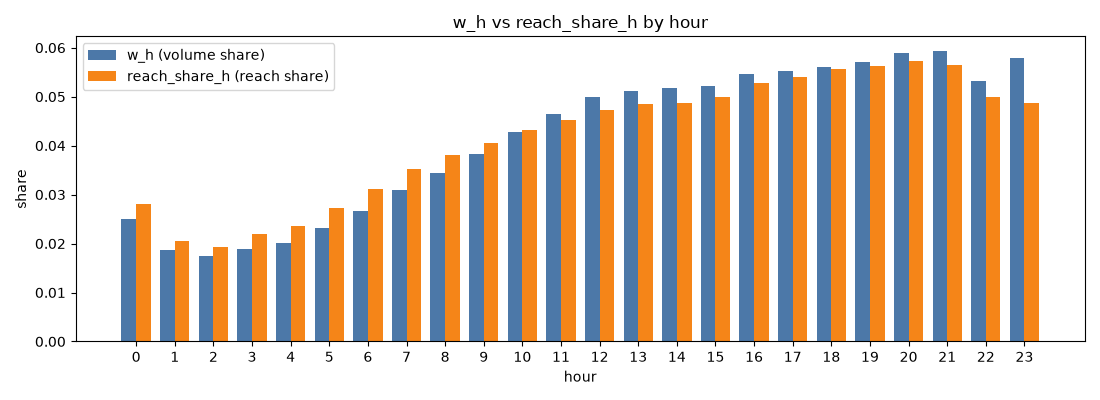

In [ ]:
x = np.arange(len(df))
width = 0.38

fig, ax = plt.subplots()
ax.bar(x - width / 2, df["w_h"], width, label="w_h (volume share)", color="#4C78A8")
ax.bar(x + width / 2, df["reach_share_h"], width, label="reach_share_h (reach share)", color="#F58518")
ax.set_xticks(x)
ax.set_xticklabels(df.index)
ax.set_xlabel("hour")
ax.set_ylabel("share")
ax.set_title("w_h vs reach_share_h by hour")
ax.legend()
plt.tight_layout()
plt.show()

## Chart 2: hourly frequency per user `freq_h` and a histogram of its variation

Left: `freq_h` by hour of day, showing when a narrow core of users browses intensively.
Right: a histogram of `freq_h` across all hours. The wider it is (rather than concentrated
around one value), the higher `CoV(freq_h)` and the stronger the support for H1.

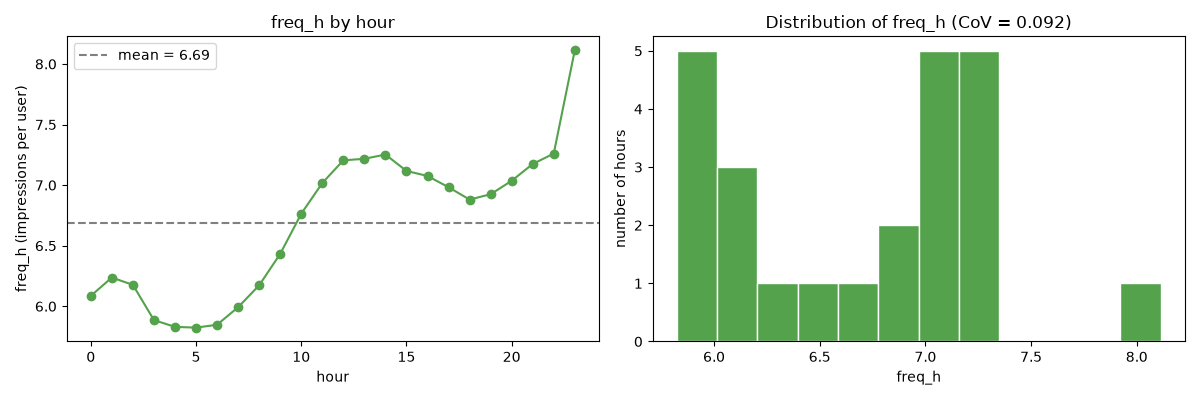

CoV(freq_h) = 0.0919  (hypothesis threshold: 0.15)


In [ ]:
freq_values = df["freq"].dropna()
cov_freq = float(freq_values.std() / freq_values.mean()) if freq_values.mean() > 0 else float("nan")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(df.index, df["freq"], marker="o", color="#54A24B")
axes[0].axhline(freq_values.mean(), color="grey", linestyle="--", label=f"mean = {freq_values.mean():.2f}")
axes[0].set_xlabel("hour")
axes[0].set_ylabel("freq_h (impressions per user)")
axes[0].set_title("freq_h by hour")
axes[0].legend()

axes[1].hist(freq_values, bins=min(12, max(3, len(freq_values))), color="#54A24B", edgecolor="white")
axes[1].set_xlabel("freq_h")
axes[1].set_ylabel("number of hours")
axes[1].set_title(f"Distribution of freq_h (CoV = {cov_freq:.3f})")

plt.tight_layout()
plt.show()

print(f"CoV(freq_h) = {cov_freq:.4f}  (hypothesis threshold: {COV_THRESHOLD})")

## Chart 3: user-segment shares by hour

Users are divided into activity segments (casual/active/superactive/bot) by quantiles of
total appearances over the period, analogous to section 5 of the main document. The stacked
chart shows the composition of `reach_h` in each hour. Varying segment proportions imply
hour-dependent reach composition (another argument for H1); stable proportions suggest
segment composition can be treated as constant (closer to H0).

In [ ]:
# segment_of, shares_df already computed in the DuckDB loading cell
segment_names = [name for name, _lo, _hi in SEGMENT_BOUNDS]
shares_df


segment,casual,active,superactive,bot
h,,,,
0,0.592525,0.134256,0.158412,0.114807
1,0.599284,0.130004,0.151400,0.119311
2,0.622663,0.126143,0.141853,0.109341
3,0.655008,0.120054,0.130308,0.094630
4,0.600721,0.154599,0.144811,0.099868
5,0.529114,0.200033,0.163220,0.107633
6,0.470223,0.228637,0.184461,0.116679
7,0.429847,0.254966,0.192985,0.122203
8,0.406313,0.268025,0.198177,0.127484


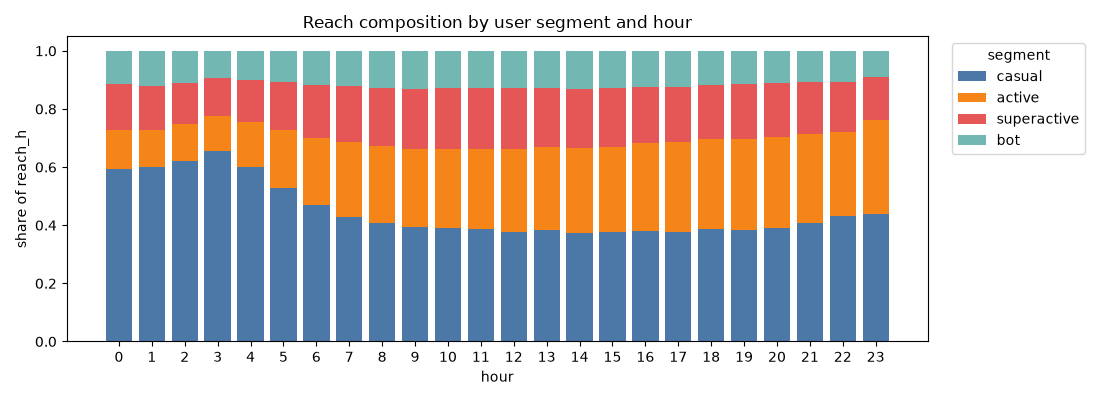

CoV of segment shares by hour (high CoV => hour-dependent reach composition):
        casual: CoV = 0.2084
        active: CoV = 0.2713
   superactive: CoV = 0.1335
           bot: CoV = 0.1027


In [ ]:
colors = {"casual": "#4C78A8", "active": "#F58518", "superactive": "#E45756", "bot": "#72B7B2"}

fig, ax = plt.subplots()
bottom = np.zeros(len(shares_df))
for name in segment_names:
    ax.bar(shares_df.index.astype(str), shares_df[name], bottom=bottom, label=name, color=colors[name])
    bottom += shares_df[name].to_numpy()

ax.set_xlabel("hour")
ax.set_ylabel("share of reach_h")
ax.set_title("Reach composition by user segment and hour")
ax.legend(title="segment", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print("CoV of segment shares by hour (high CoV => hour-dependent reach composition):")
for name in segment_names:
    series = shares_df[name]
    cov = float(series.std() / series.mean()) if series.mean() > 0 else float("nan")
    print(f"  {name:>12}: CoV = {cov:.4f}")

## Summary and verdict

In [ ]:
def pearson(a: np.ndarray, b: np.ndarray) -> float:
    if len(a) < 2 or np.std(a) == 0 or np.std(b) == 0:
        return float("nan")
    return float(np.corrcoef(a, b)[0, 1])


def spearman(a: np.ndarray, b: np.ndarray) -> float:
    def rank(x: np.ndarray) -> np.ndarray:
        order = np.argsort(x)
        ranks = np.empty_like(order, dtype=float)
        ranks[order] = np.arange(len(x))
        return ranks

    return pearson(rank(a), rank(b))


w_arr = df["w_h"].to_numpy()
reach_arr = df["reach_share_h"].to_numpy()
diff_arr = df["diff"].to_numpy()

max_diff = float(np.max(np.abs(diff_arr)))
pearson_r = pearson(w_arr, reach_arr)
spearman_r = spearman(w_arr, reach_arr)

# Total Variation distance = 1/2 * Σ|w_h - reach_share_h|. Since Σ diff = 0,
# this is exactly the share of campaign impressions assigned to the wrong hour
# when switching from volume weights w_h to reach weights: the TOTAL discrepancy
# (unlike max|diff|, which shows only the worst individual hour).
tv_distance = 0.5 * float(np.sum(np.abs(diff_arr)))
misallocated_impr = tv_distance * CAMPAIGN_VOLUME

# ---------------------------------------------------------------------------
# PRIMARY verdict: strictly follow the predeclared rule
# (hypothesis.md, step 5): H1 <=> CoV(freq_h) > COV_THRESHOLD
#                                OR max|w_h - reach_share_h| > DIFF_THRESHOLD.
# Segment-share CoV is NOT part of this rule (see exploratory block below);
# adding it after the fact would be moving the goalposts.
# ---------------------------------------------------------------------------
h1_primary = cov_freq > COV_THRESHOLD or max_diff > DIFF_THRESHOLD

print("=== Primary verdict (predeclared rule, hypothesis.md step 5) ===")
print(f"CoV(freq_h)                 = {cov_freq:.4f}  (threshold: {COV_THRESHOLD})"
      f"  -> {'H1' if cov_freq > COV_THRESHOLD else 'H0'}")
print(f"max|w_h - reach_share_h|    = {max_diff:.4f}  (threshold: {DIFF_THRESHOLD})"
      f"  -> {'H1' if max_diff > DIFF_THRESHOLD else 'H0'}")
print(f"Pearson(w_h, reach_share_h) = {pearson_r:.4f}")
print(f"Spearman(w_h, reach_share_h)= {spearman_r:.4f}")
print(f"\nVerdict (primary rule): "
      f"{'H1 (decomposition needed)' if h1_primary else 'H0 (current w_h is sufficient)'}")

# ---------------------------------------------------------------------------
# MAGNITUDE of the discrepancy in impressions: direction != practical significance.
# ---------------------------------------------------------------------------
print("\n=== Discrepancy magnitude in IMPRESSIONS ===")
print(f"Total Variation(w_h, reach_share_h) = {tv_distance:.4f}"
      f"  ({tv_distance * 100:.2f}% of campaign volume)")
print(f"  => for a {CAMPAIGN_VOLUME:,}-impression campaign, the wrong hour receives "
      f"{misallocated_impr:,.0f} impressions")
print(f"  worst individual hour: max|diff| = {max_diff:.4f}"
      f"  ({max_diff * CAMPAIGN_VOLUME:,.0f} impressions per {CAMPAIGN_VOLUME:,}-impression campaign)")

# ---------------------------------------------------------------------------
# EXPLORATORY (outside the predeclared rule): hourly segment-share CoV.
# Not part of H0/H1; measured on segments of very different sizes.
# Small segments (bot ~2%, superactive ~8%) mechanically have higher CoV due to
# sampling noise, so applying a common 0.15 threshold would be inappropriate.
# ---------------------------------------------------------------------------
segment_covs = {
    name: float(shares_df[name].std() / shares_df[name].mean())
    if shares_df[name].mean() > 0 else float("nan")
    for name in segment_names
}
print("\n=== Exploratory (NOT part of verdict): hourly segment-share CoV ===")
for name, cov in segment_covs.items():
    print(f"  CoV({name:>12}) = {cov:.4f}")
print("Interpret as an exploratory audience-composition signal, not an")
print("H0/H1 criterion. Before trusting it, check the EmptyUser diagnostics above:")
print("anonymous traffic collapses into one uid and enters 'bot', inflating its CoV.")

=== Primary verdict (predeclared rule, hypothesis.md step 5) ===
CoV(freq_h)                 = 0.0919  (threshold: 0.15)  -> H0
max|w_h - reach_share_h|    = 0.0091  (threshold: 0.05)  -> H0
Pearson(w_h, reach_share_h) = 0.9881
Spearman(w_h, reach_share_h)= 0.9809

Verdict (primary rule): H0 (current w_h is sufficient)

=== Discrepancy magnitude in IMPRESSIONS ===
Total Variation(w_h, reach_share_h) = 0.0326  (3.26% of campaign volume)
  => for a 100,000-impression campaign, the wrong hour receives 3,257 impressions
  worst individual hour: max|diff| = 0.0091  (915 impressions per campaign 100,000)

=== Exploratory (NOT part of verdict): hourly segment-share CoV ===
  CoV(      casual) = 0.2084
  CoV(      active) = 0.2713
  CoV( superactive) = 0.1335
  CoV(         bot) = 0.1027
Interpret as an exploratory audience-composition signal, not an
H0/H1 criterion. Before trusting it, check the EmptyUser diagnostics above:
anonymous traffic collapses into one uid and enters bot, inflating it

# Additional analysis

The following analysis explores the numbers above: the most active hours, drivers of higher
`freq_h`, weekday/weekend differences, and implications for traffic allocation. These cells
reuse the loaded `events`/`user_segments` materialized in DuckDB memory: **no additional full
parquet scans are needed**, except for the explicitly marked optional cell near the end.

## Most active hours

The hours with the most traffic, the most unique users, and the highest frequency per user
are not necessarily the same, as chart 1 shows.

In [ ]:
def _peak(series: pd.Series, agg: str) -> tuple[int, float]:
    h = series.idxmax() if agg == "max" else series.idxmin()
    return int(h), float(series[h])

metrics = {
    "counts (volume)": df["counts"],
    "reach (unique users)": df["reach"],
    "freq (per user)": df["freq"],
}

print(f"{'metric':<18}{'peak hr':>8}{'value':>14}{'low hr':>10}{'value':>14}")
for name, series in metrics.items():
    h_max, v_max = _peak(series, "max")
    h_min, v_min = _peak(series, "min")
    print(f"{name:<18}{h_max:>8}{v_max:>14,.1f}{h_min:>10}{v_min:>14,.1f}")

print()
for name in segment_names:
    h_max, v_max = _peak(shares_df[name], "max")
    h_min, v_min = _peak(shares_df[name], "min")
    ratio = v_max / v_min if v_min > 0 else float("nan")
    print(f"share {name:<12} peak hour {h_max:>2} ({v_max:.3f}), low hour {h_min:>2} ({v_min:.3f}), peak/low = {ratio:.2f}x")

metric            peak hr      value  low hr      value
counts (volume)          21  10,247,348.0         2   3,005,723.0
reach (unique users)           20   1,446,891.0         2     486,623.0
freq (per user)        23           8.1         5           5.8

share casual       peak hour  3 (0.655), low hour 14 (0.374), peak/low = 1.75x
share active       peak hour 23 (0.326), low hour  3 (0.120), peak/low = 2.71x
share superactive  peak hour 12 (0.211), low hour  3 (0.130), peak/low = 1.62x
share bot          peak hour 14 (0.131), low hour 23 (0.088), peak/low = 1.48x


## Correlation: what drives `freq_h`?

If the superactive/bot share of reach correlates with higher `freq_h`, the increase in
daytime/evening frequency is explained by audience composition (more frequent segments
are active then), rather than the same person generally seeing more ads in the evening.
These imply different traffic-allocation strategies: user-type segmentation in the first
case, and a purely hourly profile in the second.

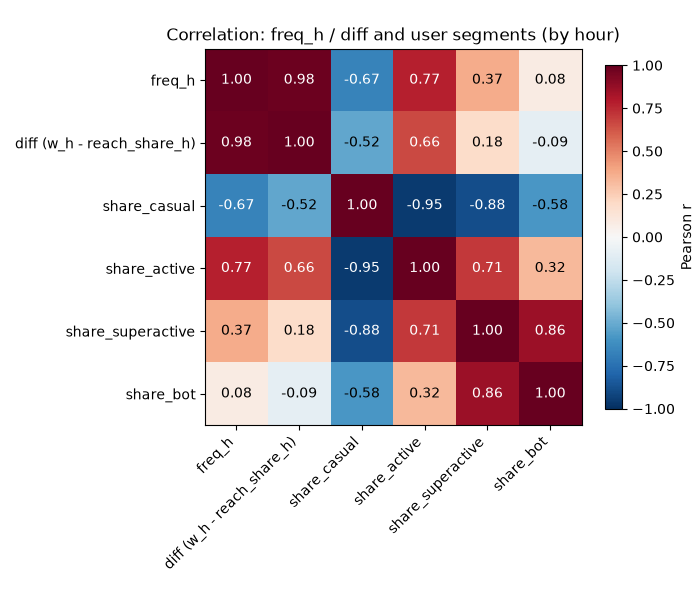

,freq_h,diff (w_h - reach_share_h),share_casual,share_active,share_superactive,share_bot
freq_h,1.000000,0.978029,-0.670235,0.773546,0.368828,0.079306
diff (w_h - reach_share_h),0.978029,1.000000,-0.517263,0.659622,0.184607,-0.093433
share_casual,-0.670235,-0.517263,1.000000,-0.953949,-0.884208,-0.584197
share_active,0.773546,0.659622,-0.953949,1.000000,0.706588,0.321357
share_superactive,0.368828,0.184607,-0.884208,0.706588,1.000000,0.855614
share_bot,0.079306,-0.093433,-0.584197,0.321357,0.855614,1.000000


In [ ]:
corr_data = pd.DataFrame({
    "freq_h": df["freq"],
    "diff (w_h - reach_share_h)": df["diff"],
    **{f"share_{name}": shares_df[name] for name in segment_names},
})
corr_matrix = corr_data.corr(method="pearson")

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr_matrix.to_numpy(), vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_xticklabels(corr_matrix.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr_matrix.columns)))
ax.set_yticklabels(corr_matrix.columns)
for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        ax.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(corr_matrix.iloc[i, j]) > 0.6 else "black")
ax.set_title("Correlation of freq_h / diff with segment shares (by hour)")
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
plt.tight_layout()
plt.show()

corr_matrix

## Weekdays vs weekends (day of week × hour)

The current `MODE = "hour_of_day"` averages Monday and Saturday into one bucket. Below is
the same reach/frequency decomposition over 7×24 = 168 buckets (`hour_of_week`), to check
whether weekdays and weekends truly behave alike or whether the profile should instead
use `hour_of_week`. The query uses the loaded `events` (`ts` holds the original timestamp),
so no additional parquet scan is needed.

Aggregating by (day_of_week, hour_of_day) from materialized `events`...


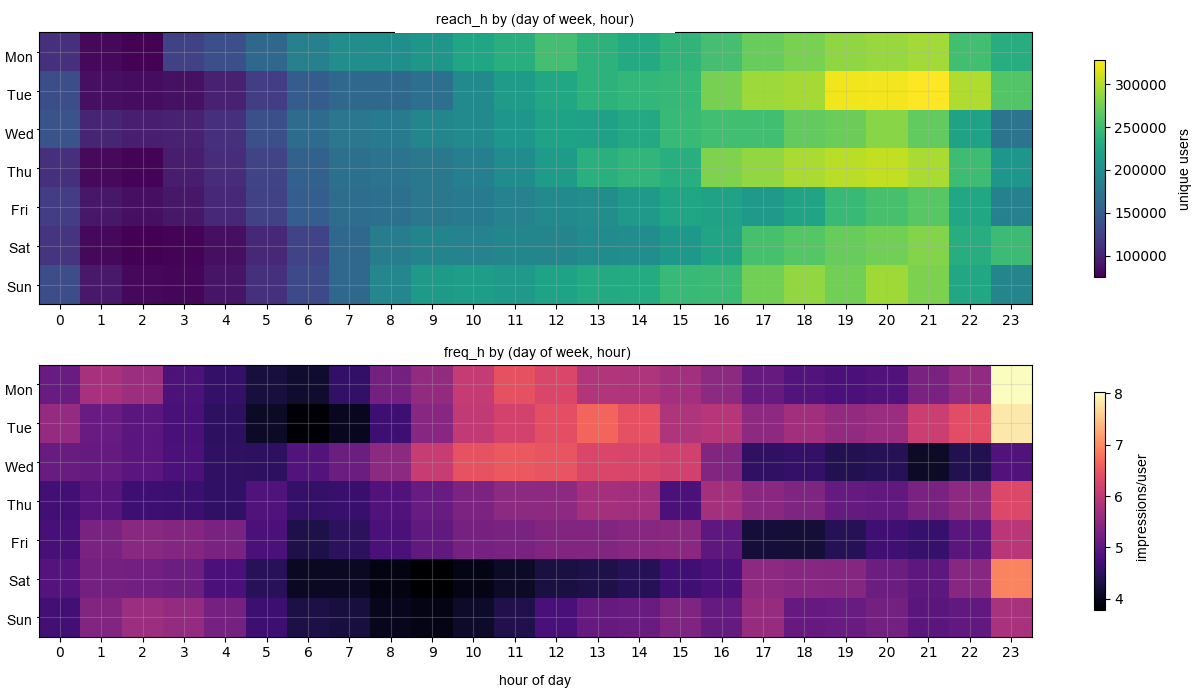

Maximum weekday/weekend freq_h difference: hour 10, weekday=5.82 vs weekend=4.05
CoV(freq_h) weekday profile:    0.1068
CoV(freq_h) weekend profile: 0.1213


In [ ]:
DAY_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]  # ts.weekday(): Mon=0 (see _get_h_type)

print("Aggregating by (day_of_week, hour_of_day) from materialized `events`...")
dow_hour = con.execute(f"""
    SELECT
        ((EXTRACT(dow FROM (ts AT TIME ZONE '{TIMEZONE}')) + 6) % 7)::INTEGER AS dow,
        EXTRACT(hour FROM (ts AT TIME ZONE '{TIMEZONE}'))::INTEGER AS hod,
        COUNT(*) AS cnt,
        COUNT(DISTINCT uid) AS reach
    FROM events
    GROUP BY dow, hod
    ORDER BY dow, hod
""").fetchdf()
dow_hour["freq"] = dow_hour["cnt"] / dow_hour["reach"]

reach_grid = dow_hour.pivot(index="dow", columns="hod", values="reach")
freq_grid = dow_hour.pivot(index="dow", columns="hod", values="freq")

fig, axes = plt.subplots(2, 1, figsize=(13, 7))

im0 = axes[0].imshow(reach_grid.to_numpy(), aspect="auto", cmap="viridis")
axes[0].set_yticks(range(7)); axes[0].set_yticklabels(DAY_NAMES)
axes[0].set_xticks(range(24)); axes[0].set_xticklabels(range(24))
axes[0].set_title("reach_h by (day of week, hour)")
fig.colorbar(im0, ax=axes[0], shrink=0.8, label="unique users")

im1 = axes[1].imshow(freq_grid.to_numpy(), aspect="auto", cmap="magma")
axes[1].set_yticks(range(7)); axes[1].set_yticklabels(DAY_NAMES)
axes[1].set_xticks(range(24)); axes[1].set_xticklabels(range(24))
axes[1].set_xlabel("hour of day")
axes[1].set_title("freq_h by (day of week, hour)")
fig.colorbar(im1, ax=axes[1], shrink=0.8, label="impressions/user")

plt.tight_layout()
plt.show()

# Weekdays (Mon-Fri) vs weekends (Sat-Sun): average hourly profile
weekday_freq = dow_hour[dow_hour["dow"] < 5].groupby("hod")["freq"].mean()
weekend_freq = dow_hour[dow_hour["dow"] >= 5].groupby("hod")["freq"].mean()
weekday_reach = dow_hour[dow_hour["dow"] < 5].groupby("hod")["reach"].sum()
weekend_reach = dow_hour[dow_hour["dow"] >= 5].groupby("hod")["reach"].sum()

diff_freq = (weekend_freq - weekday_freq)
print(f"Maximum weekday/weekend freq_h difference: hour {diff_freq.abs().idxmax()}, "
      f"weekday={weekday_freq[diff_freq.abs().idxmax()]:.2f} vs weekend={weekend_freq[diff_freq.abs().idxmax()]:.2f}")
print(f"CoV(freq_h) weekday profile: {float(weekday_freq.std() / weekday_freq.mean()):.4f}")
print(f"CoV(freq_h) weekend profile: {float(weekend_freq.std() / weekend_freq.mean()):.4f}")

## (Optional, expensive) Regional breakdown (`location`)

Russia spans multiple time zones, but `TIMEZONE = "Europe/Moscow"` is applied uniformly to
all rows. If substantial traffic comes from other zones (Yekaterinburg, Novosibirsk, etc.),
the evening peak in MSK may combine DIFFERENT local times across regions. This is a separate
source of heterogeneity, unrelated to user segments.

**This requires a separate full pass over `path` with regexp_extract (approximately 9 minutes,
as in the main loading step).** Disabled by default; enable deliberately with
`RUN_LOCATION_BREAKDOWN = True`.

In [ ]:
RUN_LOCATION_BREAKDOWN = False  # expensive extra pass over path (~9 min); enable deliberately

if RUN_LOCATION_BREAKDOWN:
    # Parse the location query parameter from the request path.
    _LOCATION_EXPR = "COALESCE(NULLIF(regexp_extract('?' || split_part(path, '?', 2), '[?&]location=([^&]*)', 1), ''), 'unknown')"
    print(f"Reading {PARQUET_FILE} for (location, hour) breakdown -- single extra full pass, ~9 min...")
    loc_hour = con.execute(f"""
        SELECT
            {_LOCATION_EXPR} AS location,
            {_HOUR_EXPR} AS h,
            COUNT(*) AS cnt,
            COUNT(DISTINCT {_USER_EXPR}) AS reach
        FROM read_parquet('{PARQUET_FILE}')
        GROUP BY location, h
    """).fetchdf()

    top_locations = (
        loc_hour.groupby("location")["reach"].sum().sort_values(ascending=False).head(10)
    )
    print("Top 10 locations by total weekly reach:")
    print(top_locations)

    # Peak-volume hour for each top location: if it differs substantially
    # across locations, regions follow different local clocks, while
    # TIMEZONE = "Europe/Moscow" is applied uniformly to all rows.
    print("\nPeak-volume hour (in TIMEZONE) for each top-10 location:")
    for loc in top_locations.index:
        sub = loc_hour[loc_hour["location"] == loc].set_index("h")["cnt"]
        print(f"  {loc:>10}: peak hour {int(sub.idxmax()):>2}, reach={int(top_locations[loc]):,}")
else:
    print("RUN_LOCATION_BREAKDOWN=False: skipping expensive extra scan (see Markdown above)")

RUN_LOCATION_BREAKDOWN=False: skipping expensive extra scan (see Markdown above)


## Implications for traffic allocation

Results are for **report-20260622**. The predeclared primary metrics yield H0: CoV(freq_h)=**0.09189348** (threshold 0.15), max|w_h − reach_share_h|=**0.00914653** (threshold 0.05), Pearson=**0.9880874**, and Spearman=**0.9808696**.

Weekly TV is **0.0325715296** (~3.257%); daily TV is **0.0325218449** (~3.252%), with daily max|diff|=**0.01254149**. The weekly and daily effects are nearly equal, about 3.25%; these results do not support a monotonic-hour bias or a 30% reduction claim.

EmptyUser contributed **1,665 of 172,638,062 events** (~0.0010%). Segment-share CoV is exploratory: casual **0.2084316**, active **0.2712659**, superactive **0.1335279**, bot **0.1026813**; these are not part of the predeclared verdict.

**Conclusion.** The primary metrics yield H0 for report-20260622. Broader conclusions require additional weeks.


In [ ]:
# === Export metrics for make_report.py ======================================
# Collect all report numbers in one JSON object, printed between
# REPORT_JSON_BEGIN/END markers. make_report.py reads THIS output (rather than
# parsing formatted cell text), keeping report generation robust against
# print-format edits. Uses globals from earlier cells (requires Run All).
import json as _json


def _peak(s):
    return {"peak_h": int(s.idxmax()), "peak": float(s.max()),
            "low_h": int(s.idxmin()), "low": float(s.min())}


REPORT = {
    "week": PARQUET_FILE.replace("\\", "/").split("/")[-1].rsplit(".", 1)[0],
    "parquet_file": PARQUET_FILE,
    "mode": MODE,
    "timezone": TIMEZONE,
    "date_start": str(min_ts),
    "date_end": str(max_ts),
    "total_records": int(total_records),
    "n_buckets": int(len(counts)),
    "cov_threshold": COV_THRESHOLD,
    "diff_threshold": DIFF_THRESHOLD,
    "campaign_volume": int(CAMPAIGN_VOLUME),
    "empty_user_events": int(_empty_events),
    "empty_user_frac": float(_empty_frac),
    "empty_user_segment": (str(_empty_seg["segment"].iloc[0]) if len(_empty_seg) else None),
    "cov_freq": float(cov_freq),
    "max_diff": float(max_diff),
    "pearson": float(pearson_r),
    "spearman": float(spearman_r),
    "h1_primary": bool(h1_primary),
    "tv_weekly": float(tv_distance),
    "misallocated_weekly": float(misallocated_impr),
    "segment_covs": {k: float(v) for k, v in segment_covs.items()},
    "peaks": {"counts": _peak(df["counts"]), "reach": _peak(df["reach"]),
              "freq": _peak(df["freq"].dropna())},
    "segment_peaks": {name: _peak(shares_df[name]) for name in segment_names},
}

# Daily denominator (if the per-day reach cell ran)
if "diff_daily" in df.columns:
    _dd = df["diff_daily"].to_numpy()
    REPORT["max_diff_daily"] = float(np.max(np.abs(_dd)))
    REPORT["tv_daily"] = float(0.5 * np.sum(np.abs(_dd)))
    REPORT["misallocated_daily"] = REPORT["tv_daily"] * CAMPAIGN_VOLUME

# Correlations of freq_h / diff with segment shares (if the correlation cell ran)
if "corr_matrix" in globals():
    _fh = corr_matrix["freq_h"]
    _dc = corr_matrix["diff (w_h - reach_share_h)"]
    REPORT["corr_freq"] = {c: float(_fh[c]) for c in corr_matrix.columns}
    REPORT["corr_diff"] = {c: float(_dc[c]) for c in corr_matrix.columns}

# Weekdays vs weekends (if the day-of-week cell ran)
if "weekday_freq" in globals() and "weekend_freq" in globals():
    REPORT["cov_freq_weekday"] = float(weekday_freq.std() / weekday_freq.mean())
    REPORT["cov_freq_weekend"] = float(weekend_freq.std() / weekend_freq.mean())

# Complete hourly table (appendix/debugging)
REPORT["table"] = {c: [float(x) for x in df[c].tolist()]
                   for c in ["counts", "reach", "freq", "w_h", "reach_share_h", "diff"]}
REPORT["table"]["h"] = [int(h) for h in df.index.tolist()]

print("REPORT_JSON_BEGIN")
print(_json.dumps(REPORT, ensure_ascii=False))
print("REPORT_JSON_END")

REPORT_JSON_BEGIN
{"week": "report-20260622", "parquet_file": "E:/Logs/report-20260622.parquet", "mode": "hour_of_day", "timezone": "Europe/Moscow", "date_start": "2026-06-22 03:00:00+03:00", "date_end": "2026-06-29 02:59:59+03:00", "total_records": 172638062, "n_buckets": 24, "cov_threshold": 0.15, "diff_threshold": 0.05, "campaign_volume": 100000, "empty_user_events": 1665, "empty_user_frac": 9.644454882724528e-06, "empty_user_segment": "bot", "cov_freq": 0.09189348287171083, "max_diff": 0.009146533559283541, "pearson": 0.9880873996327151, "spearman": 0.9808695652173912, "h1_primary": false, "tv_weekly": 0.032571529585346586, "misallocated_weekly": 3257.1529585346584, "segment_covs": {"casual": 0.2084315893450017, "active": 0.27126591520791044, "superactive": 0.13352794528174008, "bot": 0.10268134089008504}, "peaks": {"counts": {"peak_h": 21, "peak": 10247348.0, "low_h": 2, "low": 3005723.0}, "reach": {"peak_h": 20, "peak": 1446891.0, "low_h": 2, "low": 486623.0}, "freq": {"peak_h": 